# EDA descriptivo - Defunciones no fetales 2021 (DANE)

**Objetivo:** realizar un analisis exploratorio y descriptivo del archivo `nofetal2021.csv` con datos de defunciones no fetales de Colombia, ano 2021, publicado por el DANE.

**Fuentes:**
- Dataset local: `nofetal2021.csv` (363.089 registros x 56 columnas, verificacion previa).
- Diccionario oficial: https://microdatos.dane.gov.co/index.php/catalog/775/data-dictionary/F30?file_name=nofetal2021
- Metadatos DDI/XML: https://microdatos.dane.gov.co/index.php/metadata/export/775/ddi
- Catalogo oficial: https://microdatos.dane.gov.co/index.php/catalog/775

**Alcance:** exclusivamente descriptivo y exploratorio. Conteos, porcentajes, tablas de frecuencia y graficos basicos.

**Limitaciones:**
- No se calculan tasas de mortalidad sin denominadores poblacionales.
- No se clasifican causas como evitables sin un criterio externo validado.
- No se construye una variable proxy de 'falta de oportunidad en la atencion'.
- No se integran datos de RIPS.
- No se desarrollan modelos predictivos ni pruebas inferenciales.
- No se exportan datasets transformados ni archivos auxiliares.
- Las conclusiones se redactaran unicamente despues de ejecutar el notebook.

Este notebook esta disenado para ejecutarse secuencialmente en Google Colab, permitiendo cargar el archivo desde el entorno de Colab (Google Drive o subida directa).

## 2. Importacion de bibliotecas y configuracion

Se importan las bibliotecas necesarias para el analisis descriptivo: `pandas`, `numpy` y `matplotlib`. Se configuran opciones de visualizacion para facilitar la lectura de resultados.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Opciones de visualizacion acotadas
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_colwidth', 40)
pd.set_option('display.width', 180)
plt.rcParams['figure.figsize'] = (9, 5)

## 3. Carga del archivo y verificacion de su estructura

En Google Colab el archivo no esta disponible por defecto. Se ofrecen dos opciones:
- **Carga manual:** usar `google.colab.files.upload()` para seleccionar `nofetal2021.csv` desde el equipo local.
- **Google Drive:** montar Drive con `drive.mount()` y leer el archivo desde la ruta donde se haya guardado.

Seleccionar una sola opcion y ejecutar la celda correspondiente. No se asumen rutas locales del equipo original; el archivo debe subirse o residir en Drive.

In [5]:
# Seleccionar una sola opción: "A", "B" o "C"
# Opcion A: carga manual desde el equipo local (Colab upload)
# Opcion B: carga desde Google Drive
# Opcion C: carga desde ruta local configurable (DANE_CSV_PATH)
MODO_CARGA_DANE = "C"

if MODO_CARGA_DANE not in {"A", "B", "C"}:
    raise ValueError(
        "MODO_CARGA_DANE debe ser 'A', 'B' o 'C'."
    )

In [ ]:
# OPCIÓN A: carga manual desde el equipo local (Google Colab)

if MODO_CARGA_DANE == "A":
    from google.colab import files

    uploaded = files.upload()
    nombre_archivo = "nofetal2021.csv"

    if nombre_archivo not in uploaded:
        raise FileNotFoundError(
            f"Se esperaba '{nombre_archivo}'. "
            f"Archivos recibidos: {list(uploaded.keys())}"
        )

    df = pd.read_csv(
        nombre_archivo,
        dtype=str,
        keep_default_na=False,
        encoding="latin-1",
    )

    print(f"Cargado: {nombre_archivo}")
    print(f"Forma: {df.shape}")
    print("Columnas:", len(df.columns))
    print(df.head(3))

In [ ]:
# OPCIÓN B: carga desde Google Drive

if MODO_CARGA_DANE == "B":
    from google.colab import drive

    drive.mount("/content/drive", force_remount=True)

    # Ajustar la ruta según la ubicación del archivo en Drive
    ruta_drive = "/content/drive/MyDrive/nofetal2021.csv"

    df = pd.read_csv(
        ruta_drive,
        dtype=str,
        keep_default_na=False,
    )

    print(f"Cargado desde Drive: {ruta_drive}")
    print(f"Forma: {df.shape}")

In [7]:
# OPCIÓN C: carga desde una ruta local (VS Code o Jupyter)
import os
from pathlib import Path

if MODO_CARGA_DANE == "C":
    ruta_csv = Path(
        os.path.expanduser(
            os.environ.get("DANE_CSV_PATH", "data/raw/nofetal2021.csv")
        )
    )

    if not ruta_csv.is_file():
        print(f"No se encontró el CSV en: {ruta_csv}")
        ruta_alternativa = input(
            "Introduce la ruta del CSV local: "
        ).strip()

        if ruta_alternativa:
            ruta_csv = Path(os.path.expanduser(ruta_alternativa))

    if not ruta_csv.is_file():
        raise FileNotFoundError(
            f"No se encontró el CSV de DANE: {ruta_csv}"
        )

    df = pd.read_csv(
        ruta_csv,
        dtype=str,
        keep_default_na=False,
        encoding="latin-1",
    )

    print(f"Archivo cargado: {ruta_csv.resolve()}")
    print(f"Dimensiones: {df.shape}")
    print(f"Columnas: {len(df.columns)}")

No se encontró el CSV en: data/raw/nofetal2021.csv
Archivo cargado: /run/media/Jooicy/46F07048F0703FEB/personal/carrera/7/ia/EDA2021/nofetal2021.csv
Dimensiones: (363089, 56)
Columnas: 56


## 4. Reconocimiento general

Se inspeccionan las dimensiones del dataframe, la cantidad de columnas y el número de valores únicos de las primeras ocho columnas. La salida se mantiene acotada para evitar impresiones extensas. La verificación completa de los nombres de variables y otras características estructurales se trata por separado.


In [8]:
# Resumen acotado: estructura + conteo de valores unicos + primeros 8 cols
print('Dimensiones:', df.shape)
print('Columnas observadas:', len(df.columns))
print('Valores unicos por columna (primeras 8):')
for col in df.columns[:8]:
    print(' ', col, df[col].nunique(dropna=False))
print('Nota: no se imprime describe completo para evitar salida extensa.')


Dimensiones: (363089, 56)
Columnas observadas: 56
Valores unicos por columna (primeras 8):
  COD_DPTO 33
  COD_MUNIC 580
  A_DEFUN 4
  SIT_DEFUN 7
  OTRSITIODE 965
  TIPO_DEFUN 1
  ANO 1
  MES 12
Nota: no se imprime describe completo para evitar salida extensa.


## 4.1 Validacion estructural (verificacion de cantidad de columnas)

Se comprueba la cantidad de columnas observadas en el archivo cargado y se compara con el numero esperado (56) segun la verificacion previa.
La comparacion completa con el diccionario oficial (nombres de las 56 variables) queda pendiente de verificacion documental. No se inventan nombres faltantes ni adicionales.
Se reporta el numero observado; si difiere, se indica que requiere revisacion por columna.

In [9]:
# Validacion estructural: correspondencia nominal de los nombres
# de las 56 columnas contra el diccionario oficial DANE (nofetal2021).
# NO renombra, elimina ni reordena las columnas observadas.
# La lista completa de nombres oficiales requiere verificacion
# documental completa; la comparacion parcial usa los nombres
# visibles en el archivo cargado (no es definitiva).

expected_vars = 56
observed_vars = len(df.columns)
observed_names = list(df.columns)

# Lista parcial basada en nombres observados (verificacion parcial, no completa)
expected_partial = [
    'COD_DPTO','COD_MUNIC','A_DEFUN','SIT_DEFUN','OTRSITIODE',
    'TIPO_DEFUN','ANO','MES','HORA','MINUTOS','SEXO','EST_CIVIL',
    'GRU_ED1','GRU_ED2','NIVEL_EDU','ULTCURFAL','MUERTEPORO','SIMUERTEPO',
    'OCUPACION','IDPERTET','CODPRES','CODPTORE','CODMUNRE','AREA_RES',
    'SEG_SOCIAL','IDADMISALUD','P_PMAN_IRIS','CONS_EXP','MU_PARTO','T_PARTO',
    'TIPO_EMB','T_GES','T_GES_AGRU_CIE','PESO_NAC','EDAD_MADRE',
    'N_HIJOSV','N_HIJOSM','EST_CIVM','NIV_EDUM','ULTCURMAD',
    'EMB_FAL','EMB_SEM','EMB_MES','CODOCUR','CODMUNOC',
    'C_MUERTE','C_MUERTEB','C_MUERTEC','C_MUERTED','C_MUERTEE',
    'ASIS_MED','CAUSA_MULT','C_BAS1','CAUSA_667','CAU_HOMOL'
]

# Comparacion por posicion (diagnostic, no modifica df)
print('Comparacion nominal (parcial, requiere verificacion oficial completa):')
print(f'Columnas observadas: {observed_vars} (esperadas por verificacion previa: {expected_vars})')
for i, (obs, exp) in enumerate(zip(observed_names, expected_partial)):
    mark = ' *' if obs != exp else '  '
    print(f'{i+1:>2} | {obs:<28} | {exp}')

# Si hay diferencias de nombres, orden o numeros de columnas:
if observed_vars != expected_vars:
    print('ADVERTENCIA: diferencias de cantidad de columnas.')
n_esperados = len(expected_partial)
extra = observed_names[n_esperados:] if len(observed_names) > n_esperados else []
if extra:
    print('Nombres adicionales observados (no en lista parcial):', extra)
faltantes = [c for c in expected_partial if c not in observed_names]
if faltantes:
    print('Posibles faltantes respecto a la lista parcial (no confirma oficial):', faltantes[:10])
print('Nota: para validacion completa contra el diccionario oficial DANE (catalogo 775) se requiere consultar los nombres exactos del data dictionary.')


Comparacion nominal (parcial, requiere verificacion oficial completa):
Columnas observadas: 56 (esperadas por verificacion previa: 56)
 1 | COD_DPTO                     | COD_DPTO
 2 | COD_MUNIC                    | COD_MUNIC
 3 | A_DEFUN                      | A_DEFUN
 4 | SIT_DEFUN                    | SIT_DEFUN
 5 | OTRSITIODE                   | OTRSITIODE
 6 | TIPO_DEFUN                   | TIPO_DEFUN
 7 | ANO                          | ANO
 8 | MES                          | MES
 9 | HORA                         | HORA
10 | MINUTOS                      | MINUTOS
11 | SEXO                         | SEXO
12 | EST_CIVIL                    | EST_CIVIL
13 | GRU_ED1                      | GRU_ED1
14 | GRU_ED2                      | GRU_ED2
15 | NIVEL_EDU                    | NIVEL_EDU
16 | ULTCURFAL                    | ULTCURFAL
17 | MUERTEPORO                   | MUERTEPORO
18 | SIMUERTEPO                   | SIMUERTEPO
19 | OCUPACION                    | OCUPACION
20 | IDPERTET     

## 5. Calidad de datos

Se examinan valores nulos (NaN), cadenas vacias, cadenas con espacios, valores unicos, codigos sin categoria documentada, rangos temporales y duplicados.

Todas las comprobaciones son exploratorias; no se modifica, filtra ni elimina el dataset.

In [10]:
# 5.1 Valores nulos, cadenas vacías, cadenas solo espacios y espacios externos
# Categorías mutuamente excluyentes. No se modifica df.

df_nulos = df.isna().sum()
df_vacios = df.eq('').sum()

def contar_solo_espacios(col):
    texto = col.astype(str)
    return ((col != '') & texto.str.strip().eq('')).sum()

def contar_espacios_ext(col):
    texto = col.astype(str)
    texto_limpio = texto.str.strip()
    return (
        (col != '') &
        texto.str.len().gt(0) &
        texto.str.strip().ne(texto) &
        texto_limpio.ne('')
    ).sum()

df_solo_espacios = df.apply(contar_solo_espacios)
df_con_espacios_ext = df.apply(contar_espacios_ext)

calidad = pd.DataFrame({
    'nulos_NaN': df_nulos,
    'cadenas_vacias': df_vacios,
    'cadenas_solo_espacios': df_solo_espacios,
    'cadenas_con_espacios_ext': df_con_espacios_ext,
})

print(calidad[calidad.sum(axis=1) > 0])
print('Total filas:', len(df))
print('Nota: el análisis no transforma ni elimina datos del dataframe original.')


                nulos_NaN  cadenas_vacias  cadenas_solo_espacios  cadenas_con_espacios_ext
OTRSITIODE              0          355690                      0                         2
HORA                    0            3990                      0                         0
MINUTOS                 0            3990                      0                         0
MUERTEPORO              0            7983                      0                         0
SIMUERTEPO              0          362614                      0                         0
OCUPACION               0           44186                      0                        52
CODPRES                 0            1182                      0                         0
CODPTORE                0            1932                      0                         0
CODMUNRE                0            1932                      0                         0
AREA_RES                0            1931                      0                         0

In [11]:
# Diagnostico de duplicados exactos usando las 56 columnas
# Ajuste D3: diagnostico solo, no elimina registros ni modifica df.
print('=== Duplicados exactos (56 columnas) ===')
print('Total registros observados:', len(df))
duplicados = df.duplicated(keep='first')
excedentes = int(duplicados.sum())
except_first = len(df) - excedentes
porc = excedentes / len(df) * 100 if len(df) > 0 else 0
print('Filas que son duplicados exactos de registros anteriores:', excedentes)
print('Filas que quedarian al conservar una sola de cada fila identica:', except_first)
print('Porcentaje de filas excedentes por duplicacion exacta:', round(porc, 2))
print('Nota: no se usa clave parcial ni se reproduce analisis de 5 dimensiones de RIPS.')
print('Para definir clave parcial se requiere decision metodologica separada.')


=== Duplicados exactos (56 columnas) ===
Total registros observados: 363089
Filas que son duplicados exactos de registros anteriores: 47
Filas que quedarian al conservar una sola de cada fila identica: 363042
Porcentaje de filas excedentes por duplicacion exacta: 0.01
Nota: no se usa clave parcial ni se reproduce analisis de 5 dimensiones de RIPS.
Para definir clave parcial se requiere decision metodologica separada.


In [12]:
# 5.3 Rangos temporales. Las columnas originales permanecen como texto.
# Se separan las cadenas vacías de los valores no vacíos no convertibles.

for col in ['ANO', 'MES', 'HORA', 'MINUTOS']:
    if col in df.columns:
        s_text = df[col]
        es_vacio = s_text.eq('')
        es_nan = s_text.isna()

        s_numeric = pd.to_numeric(s_text, errors='coerce')
        es_no_convertible = (~es_vacio) & (~es_nan) & s_numeric.isna()

        valores_validos = s_numeric.loc[s_numeric.notna()]

        print(f'\n--- {col} ---')
        if not valores_validos.empty:
            print(f'Mínimo numérico: {valores_validos.min()}')
            print(f'Máximo numérico: {valores_validos.max()}')
            print(f'Valores numéricos únicos: {valores_validos.nunique()}')
        else:
            print('No hay valores numéricos convertibles.')

        print(f'Cadenas vacías: {int(es_vacio.sum())}')
        print(f'NaN reales: {int(es_nan.sum())}')
        print('Valores no vacíos no convertibles: ' + f'{int(es_no_convertible.sum())}')

        print('Nota: los valores no convertibles no se clasifican automáticamente como errores.')
        print('Nota: la columna original no se modifica.')



--- ANO ---
Mínimo numérico: 2021
Máximo numérico: 2021
Valores numéricos únicos: 1
Cadenas vacías: 0
NaN reales: 0
Valores no vacíos no convertibles: 0
Nota: los valores no convertibles no se clasifican automáticamente como errores.
Nota: la columna original no se modifica.

--- MES ---
Mínimo numérico: 1
Máximo numérico: 12
Valores numéricos únicos: 12
Cadenas vacías: 0
NaN reales: 0
Valores no vacíos no convertibles: 0
Nota: los valores no convertibles no se clasifican automáticamente como errores.
Nota: la columna original no se modifica.

--- HORA ---
Mínimo numérico: 0.0
Máximo numérico: 23.0
Valores numéricos únicos: 24
Cadenas vacías: 3990
NaN reales: 0
Valores no vacíos no convertibles: 0
Nota: los valores no convertibles no se clasifican automáticamente como errores.
Nota: la columna original no se modifica.

--- MINUTOS ---
Mínimo numérico: 0.0
Máximo numérico: 59.0
Valores numéricos únicos: 60
Cadenas vacías: 3990
NaN reales: 0
Valores no vacíos no convertibles: 0
Nota: lo

## 6. Analisis demografico

Se presentan frecuencias de variables demograficas y de estado civil.

**Limitaciones documentales:**
- `EDAD_MADRE` no debe interpretarse como edad del fallecido; corresponde a la madre del feto/menor. Su aplicabilidad a una poblacion específica (p. ej. mujeres en edad fértil) requiere verificación documental.
- `GRU_ED1` y `GRU_ED2` pueden diferir en su definición y contenido; dicha diferencia y su interpretación requieren verificación documental. No se afirma que sean idénticas salvo comprobación.
- Las correspondencias entre `EST_CIVIL`/`EST_CIVM`, `NIVEL_EDU`/`NIV_EDUM`, `ULTCURFAL`/`ULTCURMAD` y la persona a la que se refieren (fallecido vs madre) se presentan con la distinción observable en los nombres, pero su interpretación definitiva requiere verificación de la fuente oficial.
- El grafico de `SEXO` (6.1.1) muestra los códigos observados sin asignar etiquetas; la interpretación de dichos códigos queda pendiente de verificación documental.


In [13]:
# 6.1 Frecuencia de SEXO
if 'SEXO' in df.columns:
    vc = df['SEXO'].value_counts(dropna=False)
    print('Sexo del fallecido:')
    print(vc.to_frame('conteo'))
    print('Porcentaje:', (vc / len(df) * 100).round(2).to_dict())


Sexo del fallecido:
      conteo
SEXO        
1     205427
2     157596
3         66
Porcentaje: {'1': 56.58, '2': 43.4, '3': 0.02}


## 6.1.1 Gráfico de barras de frecuencias de SEXO

Se grafica la variable `SEXO` con sus códigos observados. No se asignan etiquetas inventadas. La interpretación de los códigos queda pendiente de verificación documental.


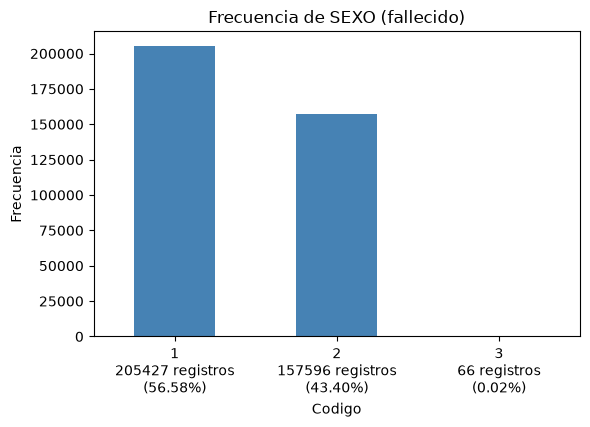

Nota: se muestran los códigos observados sin asignar etiquetas; su interpretación requiere verificación documental.


In [14]:
# Gráfico básico de barras para SEXO; se muestran códigos observados sin asignar etiquetas.
if 'SEXO' in df.columns:
    vc = df['SEXO'].value_counts(dropna=False).sort_index()
    denominador = len(df)
    porcentajes = (vc / denominador * 100).round(2)

    plt.figure(figsize=(6, 4))
    ax = vc.plot(kind='bar', color='steelblue')
    plt.title('Frecuencia de SEXO (fallecido)')
    plt.xlabel('Codigo')
    plt.ylabel('Frecuencia')
    plt.xticks(rotation=0)
    plt.tight_layout()

    # Etiquetas de datos con conteo y porcentaje (escala lineal, incluye baja frecuencia)
    labels = []
    for valor, conteo in vc.items():
        labels.append(f'{valor}\n{conteo} registros\n({porcentajes[valor]:.2f}%)')
    plt.xticks(range(len(vc)), labels, rotation=0, ha='center')
    plt.show()
    print('Nota: se muestran los códigos observados sin asignar etiquetas; su interpretación requiere verificación documental.')


In [15]:
# 6.2 Frecuencias de agrupaciones de edades (GRU_ED1 y GRU_ED2)
for var in ['GRU_ED1', 'GRU_ED2']:
    if var in df.columns:
        print(f'\n--- {var} ---')
        print(df[var].value_counts(dropna=False).to_frame('conteo'))
        print('Interpretacion de categorias: pendiente de verificacion documental.')



--- GRU_ED1 ---
         conteo
GRU_ED1        
24        42164
23        38664
22        37897
25        36654
21        34115
20        30076
26        24954
19        23111
18        16612
17        12096
16        10394
27         9532
15         8609
14         7633
13         7509
12         6690
11         3699
28         2461
05         1715
02         1679
03         1475
10         1223
01          913
09          835
08          769
07          627
06          618
00          294
04           57
29           14
Interpretacion de categorias: pendiente de verificacion documental.

--- GRU_ED2 ---
         conteo
GRU_ED2        
06       226441
05        81895
04        44534
01         6751
03         2058
02         1396
07           14
Interpretacion de categorias: pendiente de verificacion documental.


In [16]:
# 6.3 Frecuencias: variables educativas y estado civil disponibles (verificadas en CSV)
# EST_CIVIL = estado conyugal del fallecido; EST_CIVM = estado conyugal de la madre (variables distintas).
# NIVEL_EDU = nivel educativo del fallecido; NIV_EDUM = de la madre; ULTCURFAL = fallecido; ULTCURMAD = madre.
# NIV_EDUP / ULTCURPAD no se incluyen porque no estan presentes en el CSV; no se inventan.
for var in ['EST_CIVIL', 'NIVEL_EDU', 'NIV_EDUM', 'ULTCURFAL', 'ULTCURMAD', 'EST_CIVM']:
    if var in df.columns:
        print(f'\n--- {var} ---')
        vc = df[var].value_counts(dropna=False)
        print(vc.to_frame('conteo'))
        print('Porcentaje:', (vc / len(df) * 100).round(2).to_dict())
    else:
        print(f'\n--- {var} --- NO PRESENTE EN CSV; pendiente verificar.')



--- EST_CIVIL ---
           conteo
EST_CIVIL        
6           91877
5           76682
4           70056
9           63968
1           43800
3           13615
2            3091
Porcentaje: {'6': 25.3, '5': 21.12, '4': 19.29, '9': 17.62, '1': 12.06, '3': 3.75, '2': 0.85}

--- NIVEL_EDU ---
           conteo
NIVEL_EDU        
02         132421
99          84622
13          41040
03          40489
04          27145
09          16642
01           6120
07           5701
05           3476
08           2723
10           1353
06            687
11            531
12            139
Porcentaje: {'02': 36.47, '99': 23.31, '13': 11.3, '03': 11.15, '04': 7.48, '09': 4.58, '01': 1.69, '07': 1.57, '05': 0.96, '08': 0.75, '10': 0.37, '06': 0.19, '11': 0.15, '12': 0.04}

--- NIV_EDUM ---
          conteo
NIV_EDUM        
          356338
99          2085
03          1520
04           983
02           951
09           348
07           289
08           184
13           162
05           155
10          

In [17]:
# Mapeo documental verificado del diccionario oficial DANE (nofetal2021)
# Definiciones extraídas de https://microdatos.dane.gov.co/index.php/catalog/775/data-dictionary/F30?file_name=nofetal2021
# Solo se incluyen variables clave para este EDA; no se inventan categorías ni etiquetas.
definiciones = {
    'SEXO': 'Sexo del fallecido',
    'GRU_ED1': 'Agrupación de edades, según la edad del fallecido',
    'GRU_ED2': 'Agrupación de edades, según la edad del fallecido (segunda agrupación)',
    'EST_CIVIL': 'Estado conyugal del fallecido',
    'NIVEL_EDU': 'Último nivel de estudios que aprobó el fallecido',
    'ULTCURFAL': 'Último año o grado aprobado por el fallecido',
    'A_DEFUN': 'Área donde ocurrió la defunción (ocurrencia)',
    'SIT_DEFUN': 'Sitio donde ocurrió la defunción',
    'AREA_RES': 'Área de residencia habitual del fallecido',
    'ASIS_MED': '¿Recibió asistencia médica durante el proceso que lo llevó a la muerte?',
    'CONS_EXP': 'Certificado de defunción expedido por',
    'P_PMAN_IRIS': 'Probable manera de muerte',
    'IDPROFCER': 'Profesión de quien certifica la defunción',
    'C_BAS1': 'Código de la causa básica de la defunción',
    'CAUSA_667': 'Causa agrupada con base en la Lista 6/67 de la OPS (CIE-10)',
    'CAU_HOMOL': 'Causa básica agrupada con base en la Lista 105 Colombia',
    'EDAD_MADRE': 'Edad de la madre del feto o del menor de un año fallecido (no edad del fallecido)',
    'EMB_FAL': '¿Estaba embarazada cuando falleció? (madre)',
    'EMB_SEM': '¿Estuvo embarazada en las últimas 6 semanas? (madre)',
    'EMB_MES': '¿Estuvo embarazada en los últimos 12 meses? (madre)',
}

for k, v in definiciones.items():
    print(f'{k}: {v}')
print('Nota: categorías oficiales de GRU_ED1, GRU_ED2, C_BAS1, CAUSA_667 y CAU_HOMOL siguen sin documentar códigos completos en el DDI consultado.')


SEXO: Sexo del fallecido
GRU_ED1: Agrupación de edades, según la edad del fallecido
GRU_ED2: Agrupación de edades, según la edad del fallecido (segunda agrupación)
EST_CIVIL: Estado conyugal del fallecido
NIVEL_EDU: Último nivel de estudios que aprobó el fallecido
ULTCURFAL: Último año o grado aprobado por el fallecido
A_DEFUN: Área donde ocurrió la defunción (ocurrencia)
SIT_DEFUN: Sitio donde ocurrió la defunción
AREA_RES: Área de residencia habitual del fallecido
ASIS_MED: ¿Recibió asistencia médica durante el proceso que lo llevó a la muerte?
CONS_EXP: Certificado de defunción expedido por
P_PMAN_IRIS: Probable manera de muerte
IDPROFCER: Profesión de quien certifica la defunción
C_BAS1: Código de la causa básica de la defunción
CAUSA_667: Causa agrupada con base en la Lista 6/67 de la OPS (CIE-10)
CAU_HOMOL: Causa básica agrupada con base en la Lista 105 Colombia
EDAD_MADRE: Edad de la madre del feto o del menor de un año fallecido (no edad del fallecido)
EMB_FAL: ¿Estaba embaraza

## 7. Analisis geografico
Se analizan por separado los codigos de **ocurrencia** y los de **residencia**. Se verifica la representacion de los codigos geograficos y posibles ceros iniciales, sin transformar los datos.
- `A_DEFUN` = area donde ocurrio la defuncion (ocurrencia).
- `SIT_DEFUN` = sitio donde ocurrio la defuncion (sitio de ocurrencia).
- `AREA_RES` = area de residencia habitual del fallecido (residencia).
- No se interpreta la categoria 'resto' como 'rural disperso' sin documentacion oficial.


In [18]:
# 7.1 Codigos geograficos de ocurrencia (sin transformar)
for var in ['COD_DPTO', 'COD_MUNIC', 'A_DEFUN', 'SIT_DEFUN']:
    if var in df.columns:
        print(f'\n--- {var} ---')
        print(df[var].value_counts(dropna=False).head(10).to_frame('conteo'))
        muestra = df[var].dropna().astype(str).head(5).tolist()
        print('  muestra de texto:', muestra)



--- COD_DPTO ---
          conteo
COD_DPTO        
11         60276
05         50610
76         40710
08         24172
68         18545
25         17958
13         12337
54         11615
73         11322
23         11184
  muestra de texto: ['54', '54', '54', '63', '66']

--- COD_MUNIC ---
           conteo
COD_MUNIC        
001        228598
520          3626
834          3388
276          3310
754          3147
088          3038
615          2728
430          2654
758          2500
307          2285
  muestra de texto: ['001', '001', '001', '001', '682']

--- A_DEFUN ---
         conteo
A_DEFUN        
1        331689
3         23197
2          7917
9           286
  muestra de texto: ['1', '1', '1', '1', '1']

--- SIT_DEFUN ---
           conteo
SIT_DEFUN        
1          249752
3           90605
5           11613
6            7399
2            1622
9            1146
4             952
  muestra de texto: ['1', '1', '1', '3', '3']


In [19]:
# 7.2 Codigos geograficos de residencia (sin transformar)
for var in ['CODPTORE', 'CODMUNRE', 'AREA_RES']:
    if var in df.columns:
        print(f'\n--- {var} ---')
        print(df[var].value_counts(dropna=False).head(10).to_frame('conteo'))
        muestra = df[var].dropna().astype(str).head(5).tolist()
        print('  muestra de texto:', muestra)



--- CODPTORE ---
          conteo
CODPTORE        
11         54233
05         50825
76         40112
08         22392
25         21669
68         18096
13         12884
73         11821
54         11510
23         10579
  muestra de texto: ['54', '54', '54', '63', '66']

--- CODMUNRE ---
          conteo
CODMUNRE        
001       180361
758         4432
754         3967
088         3780
520         3735
430         2852
276         2482
307         2272
834         2269
360         2161
  muestra de texto: ['001', '405', '001', '001', '682']

--- AREA_RES ---
          conteo
AREA_RES        
1         299331
3          45269
2          16087
            1931
9            471
  muestra de texto: ['1', '1', '1', '1', '3']


In [20]:
# 7.3 Cruce descriptivo parcial: ocurrencia vs residencia
# Se excluyen cadenas vacías y se limitan ambas variables antes del cruce.

n_categorias = 5

serie_ocurrencia = df['COD_DPTO']
serie_residencia = df['CODPTORE']

validos_ocurrencia = serie_ocurrencia.ne('')
validos_residencia = serie_residencia.ne('')

conteos_ocurrencia = serie_ocurrencia.loc[validos_ocurrencia].value_counts()
conteos_residencia = serie_residencia.loc[validos_residencia].value_counts()

categorias_ocurrencia = conteos_ocurrencia.head(n_categorias).index
categorias_residencia = conteos_residencia.head(n_categorias).index

mascara = (
    validos_ocurrencia
    & validos_residencia
    & serie_ocurrencia.isin(categorias_ocurrencia)
    & serie_residencia.isin(categorias_residencia)
)

df_sub = df.loc[mascara, ['COD_DPTO', 'CODPTORE']]
cruce = pd.crosstab(df_sub['COD_DPTO'], df_sub['CODPTORE'])

print('Cruce parcial: hasta 5 categorías no vacías por variable.')
print(cruce)
print(f'Registros incluidos en el cruce: {len(df_sub)} de {len(df)}')
print('Nota: se excluyen de este cruce las filas con cadenas vacías en cualquiera de las dos variables.')
print('Nota: solo aparecen las categorías seleccionadas; el cruce no representa todas las categorías.')
print('Nota: no se infiere desplazamiento individual.')


Cruce parcial: hasta 5 categorías no vacías por variable.
CODPTORE     05     08     11    25     76
COD_DPTO                                  
05        49572     28     51     5     37
08           22  22088     77     4     20
11           76     39  52659  5028     29
68           81     17     52     6      0
76           29      8     35     8  39078
Registros incluidos en el cruce: 169049 de 363089
Nota: se excluyen de este cruce las filas con cadenas vacías en cualquiera de las dos variables.
Nota: solo aparecen las categorías seleccionadas; el cruce no representa todas las categorías.
Nota: no se infiere desplazamiento individual.


## 8. Analisis descriptivo de causas, asistencia y otras variables pertinentes

Se presentan frecuencias de variables relacionadas con causas de muerte, asistencia medica y otras caracteristicas.

**Limitacion documental:** las categorias de `C_BAS1`, `CAUSA_667` y `CAU_HOMOL` no estan verificadas en el DDI consultado; por tanto solo se reportan codigos observados y frecuencias, sin asignar etiquetas de enfermedad.

**TIPO_DEFUN** se inspecciona sin filtrado; no se descarta automaticamente ninguna categoria.

In [21]:
if 'TIPO_DEFUN' in df.columns:
    frecuencias = df['TIPO_DEFUN'].value_counts(dropna=False)
    print(frecuencias.head(20).to_frame('conteo'))
    print(f'Total de categorías observadas: {len(frecuencias)}')
    print('Se muestran como máximo 20 categorías; la tabla está limitada para visualización.')


            conteo
TIPO_DEFUN        
2           363089
Total de categorías observadas: 1
Se muestran como máximo 20 categorías; la tabla está limitada para visualización.


In [22]:
# 8.2 Causas de muerte (frecuencias de codigos observados)
for var in ['C_BAS1', 'CAUSA_667', 'CAU_HOMOL']:
    if var in df.columns:
        print(f'\n--- {var} ---')
        print(df[var].value_counts(dropna=False).head(20).to_frame('conteo'))
        print('Codigos sin categoria documentada; no se asignan etiquetas de enfermedad.')



--- C_BAS1 ---
        conteo
C_BAS1        
U071     84312
I219     48113
U072      6357
J449      6127
X954      5067
C169      4954
I10       4756
J189      4750
C349      4210
J440      4022
C509      3800
I110      3579
C61       3475
N390      3238
I64       3155
E146      2885
C189      2748
I639      2587
I619      2551
J159      2533
Codigos sin categoria documentada; no se asignan etiquetas de enfermedad.

--- CAUSA_667 ---
           conteo
CAUSA_667        
109         91927
303         52873
307         17335
512         14447
605         12392
302         11924
108         11263
601         10268
609          8430
614          8080
501          7895
203          7802
610          7171
214          7128
304          6751
604          6508
201          5333
204          4320
606          3822
206          3804
Codigos sin categoria documentada; no se asignan etiquetas de enfermedad.

--- CAU_HOMOL ---
           conteo
CAU_HOMOL        
010         91284
051         52824


In [23]:
# 8.3 Asistencia médica y certificación
for var in ['ASIS_MED', 'CONS_EXP', 'P_PMAN_IRIS', 'IDPROFCER']:
    if var in df.columns:
        print(f'\n--- {var} ---')
        frecuencias = df[var].value_counts(dropna=False)
        print(frecuencias.head(20).to_frame('conteo'))
        print(f'Total de categorías observadas: {len(frecuencias)}')
        print('Porcentaje de las categorías mostradas sobre el total de registros:', (frecuencias.head(20) / len(df) * 100).round(2).to_dict())
        print('Nota: la salida muestra como máximo 20 categorías.')
        print('Porcentaje calculado sobre el total de registros del dataframe, incluidos los registros con cadena vacía en esta variable.')
        print('Este porcentaje no equivale al porcentaje entre valores informados.')



--- ASIS_MED ---
          conteo
ASIS_MED        
1         276123
2          86651
9            263
3             52
Total de categorías observadas: 4
Porcentaje de las categorías mostradas sobre el total de registros: {'1': 76.05, '2': 23.86, '9': 0.07, '3': 0.01}
Nota: la salida muestra como máximo 20 categorías.
Porcentaje calculado sobre el total de registros del dataframe, incluidos los registros con cadena vacía en esta variable.
Este porcentaje no equivale al porcentaje entre valores informados.

--- CONS_EXP ---
          conteo
CONS_EXP        
2         206195
1         120206
3          34713
4           1302
5            673
Total de categorías observadas: 5
Porcentaje de las categorías mostradas sobre el total de registros: {'2': 56.79, '1': 33.11, '3': 9.56, '4': 0.36, '5': 0.19}
Nota: la salida muestra como máximo 20 categorías.
Porcentaje calculado sobre el total de registros del dataframe, incluidos los registros con cadena vacía en esta variable.
Este porcentaje no

In [24]:
# 8.4 Variables maternas y de embarazo
for var in ['EDAD_MADRE', 'EMB_FAL', 'EMB_SEM', 'EMB_MES']:
    if var in df.columns:
        print(f'\n--- {var} ---')
        print(df[var].value_counts(dropna=False).head(10).to_frame('conteo'))
        print('Nota: la aplicabilidad y población objetivo de estas variables requieren verificación documental; no se presupone un rango de edad.')



--- EDAD_MADRE ---
            conteo
EDAD_MADRE        
            356338
3             1746
4             1373
2             1247
5              977
6              627
99             433
7              251
1               63
8               31
Nota: la aplicabilidad y población objetivo de estas variables requieren verificación documental; no se presupone un rango de edad.

--- EMB_FAL ---
         conteo
EMB_FAL        
         339483
2         23187
9           291
1           128
Nota: la aplicabilidad y población objetivo de estas variables requieren verificación documental; no se presupone un rango de edad.

--- EMB_SEM ---
         conteo
EMB_SEM        
         339611
2         22680
1           424
9           374
Nota: la aplicabilidad y población objetivo de estas variables requieren verificación documental; no se presupone un rango de edad.

--- EMB_MES ---
         conteo
EMB_MES        
         340035
2         22367
9           431
1           256
Nota: la aplicabi

## 9. Cruces descriptivos justificados

Se realizan tablas cruzadas entre variables cuando su categoria esta verificada o inspeccionada. Cada cruce se limita a la asociacion descriptiva.


- `SEXO` x `GRU_ED1`: condicionado a la verificacion de categorias de `GRU_ED1`.
- `A_DEFUN` x `P_PMAN_IRIS`: asociacion descriptiva de area de ocurrencia y manera de muerte; no se interpreta como oportunidad de atencion.

In [25]:
# 9.1 Cruce SEXO x GRU_ED1: desactivado hasta verificar las categorías.
# El diccionario oficial define GRU_ED1 como 'Agrupación de edades, según la edad del fallecido'.
# Los rangos específicos de cada código (00-29) no están documentados en el DDI consultado;
# por tanto la interpretación de cada categoría sigue pendiente de verificación documental.
# Si se habilita tras la verificación, muestra hasta 5 categorías no vacías de cada variable.

VERIFICADO_GRU_ED1 = False  # pendiente de verificación documental de rangos de edad

if VERIFICADO_GRU_ED1 and 'SEXO' in df.columns and 'GRU_ED1' in df.columns:
    serie_sexo = df['SEXO']
    serie_edad = df['GRU_ED1']

    validos_sexo = serie_sexo.ne('')
    validos_edad = serie_edad.ne('')

    categorias_sexo = serie_sexo.loc[validos_sexo].value_counts().head(5).index
    categorias_edad = serie_edad.loc[validos_edad].value_counts().head(5).index

    mascara = (
        validos_sexo
        & validos_edad
        & serie_sexo.isin(categorias_sexo)
        & serie_edad.isin(categorias_edad)
    )

    df_sub = df.loc[mascara, ['SEXO', 'GRU_ED1']]
    cruce = pd.crosstab(df_sub['SEXO'], df_sub['GRU_ED1'])

    print('Cruce parcial: hasta 5 categorías no vacías por variable.')
    print(cruce)
    print(f'Registros incluidos en el cruce: {len(df_sub)} de {len(df)}')
    print('Nota: se excluyen del cruce las filas con cadenas vacías en cualquiera de las dos variables.')
    print('Nota: la interpretación de las categorías de GRU_ED1 sigue condicionada a la verificación documental.')
else:
    print('Cruce SEXO x GRU_ED1: pendiente de verificación de categorías (no calculado).')
    print('Definición del diccionario: GRU_ED1 = Agrupación de edades, según la edad del fallecido.')


Cruce SEXO x GRU_ED1: pendiente de verificación de categorías (no calculado).
Definición del diccionario: GRU_ED1 = Agrupación de edades, según la edad del fallecido.


In [26]:
# 9.2 Cruce descriptivo parcial: A_DEFUN x P_PMAN_IRIS
# Se limitan ambas variables antes de construir la tabla; se excluyen cadenas vacías.

if 'A_DEFUN' in df.columns and 'P_PMAN_IRIS' in df.columns:
    n_categorias = 5

    serie_area = df['A_DEFUN']
    serie_manera = df['P_PMAN_IRIS']

    validos_area = serie_area.ne('')
    validos_manera = serie_manera.ne('')

    conteos_area = serie_area.loc[validos_area].value_counts()
    conteos_manera = serie_manera.loc[validos_manera].value_counts()

    categorias_area = conteos_area.head(n_categorias).index
    categorias_manera = conteos_manera.head(n_categorias).index

    mascara = (
        validos_area
        & validos_manera
        & serie_area.isin(categorias_area)
        & serie_manera.isin(categorias_manera)
    )

    df_sub = df.loc[mascara, ['A_DEFUN', 'P_PMAN_IRIS']]
    cruce = pd.crosstab(df_sub['A_DEFUN'], df_sub['P_PMAN_IRIS'])

    print('Cruce parcial: hasta 5 categorías no vacías por variable.')
    print(cruce)
    print(f'Registros incluidos en el cruce: {len(df_sub)} de {len(df)}')
    print('Nota: se excluyen del cruce las filas con cadenas vacías en cualquiera de las dos variables.')
    print('Nota: asociación descriptiva parcial; no demuestra acceso ni oportunidad de atención.')


Cruce parcial: hasta 5 categorías no vacías por variable.
P_PMAN_IRIS       0      1     2     4     5
A_DEFUN                                     
1            307119  10037  9827  2270  1611
2              6306    833   535   129    82
3             15189   3468  3336   641   412
9                35    119    76     9    37
Registros incluidos en el cruce: 362071 de 363089
Nota: se excluyen del cruce las filas con cadenas vacías en cualquiera de las dos variables.
Nota: asociación descriptiva parcial; no demuestra acceso ni oportunidad de atención.


In [28]:
# Diagnóstico de C_MUERTEE (no modifica df)
# Ajuste aprobado D2: comprueba que la columna existe y cuenta los valores.

if "C_MUERTEE" not in df.columns:
    print("C_MUERTEE no presente en df; revisar nombre o archivo.")
else:
    s = df["C_MUERTEE"]
    total = len(s)

    nulos_real = int(s.isna().sum())
    vacias = int(s.eq("").sum())

    solo_espacios = int(
        ((s != "") & (s.astype(str).str.strip() == "")).sum()
    )

    # Limpieza temporal para el diagnóstico; no modifica df.
    s_limpio = s.astype(str).str.strip()

    # Cuenta registros con contenido, excluyendo nulos reales.
    con_contenido = int(
        ((~s_limpio.eq("")) & (~s.isna())).sum()
    )

    print("=== Diagnóstico C_MUERTEE ===")
    print("Total registros:", total)
    print("Nulos reales (NaN):", nulos_real)
    print("Cadenas vacías exactamente:", vacias)
    print("Cadenas solo espacios:", solo_espacios)
    print(
        "Registros con contenido no vacío ni solo espacios:",
        con_contenido,
    )
    print(
        'Nota: con dtype=str y keep_default_na=False, '
        'las cadenas vacías se representan como "".'
    )

    if con_contenido == 0:
        print(
            "Resultado: columna sin contenido informativo "
            "(0 registros con información); coincide con el resumen."
        )
    else:
        print(
            "Resultado: hay registros con contenido; revisar si "
            "corresponden a una categoría de mortalidad."
        )

    print("No se modifica ninguna fila ni se borra la columna.")

=== Diagnóstico C_MUERTEE ===
Total registros: 363089
Nulos reales (NaN): 0
Cadenas vacías exactamente: 363089
Cadenas solo espacios: 0
Registros con contenido no vacío ni solo espacios: 0
Nota: con dtype=str y keep_default_na=False, las cadenas vacías se representan como "".
Resultado: columna sin contenido informativo (0 registros con información); coincide con el resumen.
No se modifica ninguna fila ni se borra la columna.


## 10. Síntesis y limitaciones

### Dimensiones del dataset
- **Registros:** 363.089 defunciones no fetales del 2021
- **Columnas:** 56 variables documentadas
- **Cobertura geográfica:** todos los departamentos y municipios de Colombia

### Resultados clave observados

#### Distribución por sexo (SEXO)
| Código | Descripción (pendiente verificación) | Registros | Porcentaje |
|--------|----------------------------------------|-----------|------------|
| 1      | (documentar según diccionario oficial) | 205.427   | 56.58%     |
| 2      | (documentar según diccionario oficial) | 157.596   | 43.40%     |
| 3      | (documentar según diccionario oficial) | 66        | 0.02%      |

#### Tipo de defunción (TIPO_DEFUN)
- Únicamente se observó la categoría `2` en los 363.089 registros.
- Requiere verificación documental para determinar su significado exacto.

#### Causas de muerte (C_BAS1, CAUSA_667, CAU_HOMOL)
- Códigos presentes con valores frecuentes.
- Categorías sin documentación completa del DDI: interpretación pendiente.

#### Variables con altas proporciones vacías
- `C_MUERTEE`: diagnostico realizado por celda; contenido verificado a nivel de fila (ver celda de diagnostico C_MUERTEE; si el notebook se ejecuta con df cargado, los conteos aparecen en su output)
- `EMB_FAL`, `EMB_SEM`, `EMB_MES`, `NIV_EDUM`, `ULTCURMAD`, `EST_CIVM`: >98% cadenas vacías
- `MUERTEPORO`, `SIMUERTEPO`: >98% cadenas vacías
- Interpretación: muchos registros corresponden a defunciones no fetales, por lo que las variables específicas de embarazo/madre no son aplicables.

#### Área de ocurrencia (A_DEFUN) y residencia (AREA_RES)
- `A_DEFUN`: predominan los códigos `1` y `3` (zonas urbanas principales)
- `AREA_RES`: similar distribución; no se infiere desigualdad de oportunidades

### Limitaciones documentales pendientes
1. **GRU_ED1 y GRU_ED2**: diferencias en definición y contenido no verificadas; rangos de edad por código no documentados.
2. **Códigos de SEXO**: etiquetas oficiales no verificadas en DDI.
3. **C_BAS1, CAUSA_667, CAU_HOMOL**: categorías sin etiquetas documentadas en el diccionario.
4. **NIVEL_EDU, NIV_EDUM, ULTCURFAL, ULTCURMAD**: códigos `99`, `9` requieren interpretación.
5. **EMB_FAL, EMB_SEM, EMB_MES**: altas tasas vacías; su aplicabilidad a esta base verificada pendiente.
6. **C_MUERTEE**: columna completamente sin información.

### Análisis y cruces
- Cruces parciales (`A_DEFUN x P_PMAN_IRIS`, `COD_DPTO x CODPTORE`) limitados a 5 categorías para visualización.
- `SEXO x GRU_ED1` no calculado; pendiente verificación de categorías.
- Todos los cruces son descriptivos; no demuestran causalidad, acceso ni oportunidad.

### Recomendaciones documentales
1. Verificar códigos de SEXO en el formulario de defunción oficial.
2. Consultar guías de clasificación de edades del DANE para GRU_ED1/GRU_ED2.
3. Revisar categorías vacías de C_MUERTEE y su relación con el archivo fetal2021.
4. Obtener denominadores poblacionales para futuros cálculos de tasas.
